# Length of stay: Neural network (MLP)

A feed-forward neural network: one hidden layer of 100 ReLU units, Adam optimizer, 200 epochs. It may warn that it has not fully converged at 200 epochs; that is part of the untuned setting. This is the slowest model here (~2–3 min).

**Task:** predict an animal's length-of-stay bin at intake: `<1 week`, `1-4 weeks`, `1-3 months`, `3+ months`. The bins are ordinal.
**Data:** Austin dogs and cats, intake-time features only (`utils.FEATURES`). Train is intakes before 2022 and val is 2022, grouped by animal (see `eda/austindataprocessing.ipynb`).
**Metrics:** accuracy, macro-F1, per-class precision/recall, and quadratic weighted kappa (QWK; rewards predictions that land close to the true bin).
**This notebook uses default hyperparameters** (no tuning). The only exceptions are settings that don't change the model itself: `random_state=utils.SEED`, `n_jobs=-1`, and an iteration cap where the default fails to converge. Tuning comes later.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # repo root -> import utils
import utils

RESULTS_DIR = Path("results")
train, val, test = utils.load_los_splits()   # test is held out; models are compared on val
print(f"train {len(train):,}  val {len(val):,}  (test {len(test):,} untouched)")
train["los_bin"].value_counts(normalize=True).reindex(utils.LOS_BIN_LABELS).round(3)

time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split
train 126,758  val 10,544  (test 21,835 untouched)


los_bin
<1 week       0.559
1-4 weeks     0.262
1-3 months    0.139
3+ months     0.040
Name: proportion, dtype: float64

In [2]:
from sklearn.neural_network import MLPClassifier

model = MLPClassifier(random_state=utils.SEED)
model

,hidden_layer_sizes,"(100,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,200
,shuffle,True
,random_state,42


/opt/homebrew/anaconda3/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


== Neural network (MLP) ==  macro-F1 0.375  accuracy 0.486
              precision    recall  f1-score   support

     <1 week       0.60      0.60      0.60      4554
   1-4 weeks       0.42      0.48      0.45      3420
  1-3 months       0.38      0.35      0.37      2017
   3+ months       0.20      0.06      0.09       553

    accuracy                           0.49     10544
   macro avg       0.40      0.37      0.37     10544
weighted avg       0.48      0.49      0.48     10544

quadratic weighted kappa: 0.310


train accuracy 0.674  |  fit 179.1s  predict 0.0s


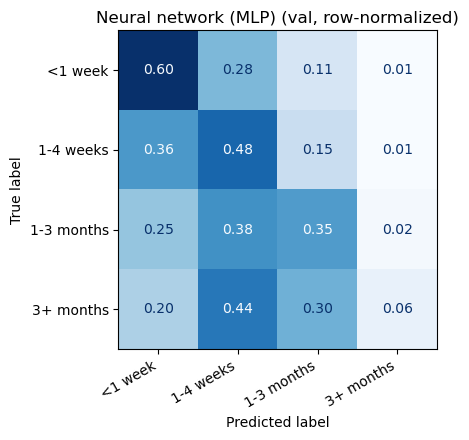

In [3]:
pipe, metrics = utils.evaluate_classifier(model, train, val, name="Neural network (MLP)",
                                           results_dir=RESULTS_DIR)

## Hyperparameter tuning (light–medium)

**Randomized search with a time-ordered inner split** (`utils.tune_classifier`):
- Training years are split again, by time and grouped by animal: candidates are fit on intakes before 2021 and scored on 2021 intakes.
- Candidates are ranked by **macro-F1**, so all four bins count equally, not just the dominant `<1 week`.
- The best setting is then refit on the full training set (< 2022) and scored on the **same 2022 val set** as the untuned model.
- Neither val nor test is seen during the search, so the comparison below is fair.

Searched: architecture (1–2 hidden layers), L2 penalty, learning rate, and batch size. Early stopping is always on, which also fixes the convergence warning and cuts training time. `MLPClassifier` has no `class_weight` option.

In [4]:
from scipy.stats import loguniform

# SafeMLPClassifier = MLPClassifier + a fix for a scikit-learn 1.7 bug with early_stopping and string labels
base = utils.SafeMLPClassifier(**model.get_params())
space = {
    'hidden_layer_sizes': [(64,), (100,), (128, 64), (256, 128)],
    'alpha': loguniform(1e-5, 1e-1),          # L2 penalty
    'learning_rate_init': loguniform(1e-4, 1e-2),
    'batch_size': [200, 512],
    'early_stopping': [True],                 # stop when an internal 10% split stops improving
}

best, search_results, tune_info = utils.tune_classifier(
    base, space, train, name="Neural network (MLP) (tuned)", n_iter=10, results_dir=RESULTS_DIR)
search_results.head(10)

time_group_split: dropped 592 rows (0.5%) belonging to animals first seen in an earlier split


Neural network (MLP) (tuned): 10 candidates in 0.6 min | sub-train 115,479, inner-val 10,687 | best inner-val f1_macro 0.395
best params: {'alpha': 0.0005342937261279777, 'batch_size': 200, 'early_stopping': True, 'hidden_layer_sizes': [128, 64], 'learning_rate_init': 0.0016738085788752138}


,alpha,batch_size,early_stopping,hidden_layer_sizes,learning_rate_init,inner_val_f1_macro,mean_fit_time
0,0.000534,200,True,"(128, 64)",0.001674,0.394613,18.947165
1,0.006797,512,True,"(64,)",0.008706,0.387590,8.726536
2,0.000315,200,True,"(128, 64)",0.002911,0.386182,21.320458
3,0.000017,512,True,"(64,)",0.001593,0.385590,14.267469
4,0.000054,512,True,"(100,)",0.001121,0.382050,19.409314
5,0.000667,200,True,"(100,)",0.000251,0.369835,33.733180
6,0.002481,200,True,"(100,)",0.000205,0.367861,27.357042
7,0.021368,512,True,"(100,)",0.000231,0.365993,26.204122
8,0.000036,512,True,"(256, 128)",0.000540,0.361790,32.577904
9,0.001140,512,True,"(64,)",0.000124,0.327604,20.214012


== Neural network (MLP) (tuned) ==  macro-F1 0.364  accuracy 0.514
              precision    recall  f1-score   support

     <1 week       0.59      0.69      0.64      4554
   1-4 weeks       0.43      0.52      0.47      3420
  1-3 months       0.47      0.24      0.31      2017
   3+ months       0.21      0.02      0.03       553

    accuracy                           0.51     10544
   macro avg       0.42      0.37      0.36     10544
weighted avg       0.50      0.51      0.49     10544

quadratic weighted kappa: 0.298


train accuracy 0.642  |  fit 22.3s  predict 0.0s


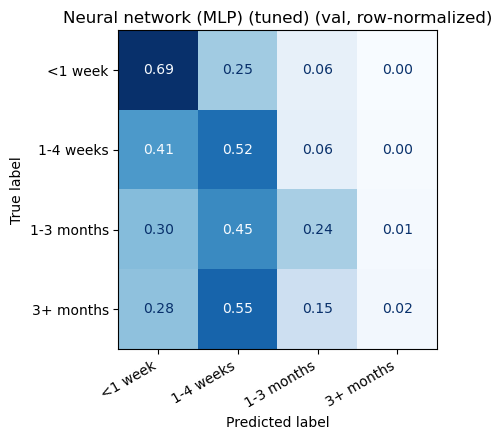

In [5]:
tuned = utils.with_params(base, best)
pipe_tuned, metrics_tuned = utils.evaluate_classifier(
    tuned, train, val, name="Neural network (MLP) (tuned)", results_dir=RESULTS_DIR, extra=tune_info)

### Untuned vs. tuned (val 2022)

In [6]:
pd.DataFrame([metrics, metrics_tuned]).set_index("model")[
    ["accuracy", "macro_f1", "qwk", "train_accuracy"]
    + [f"recall_{c}" for c in utils.LOS_BIN_LABELS]].round(3)

,accuracy,macro_f1,qwk,train_accuracy,recall_<1 week,recall_1-4 weeks,recall_1-3 months,recall_3+ months
model,,,,,,,,
Neural network (MLP),0.486,0.375,0.310,0.674,0.602,0.478,0.353,0.056
Neural network (MLP) (tuned),0.514,0.364,0.298,0.642,0.690,0.524,0.237,0.018
